# Practical Session 4.1: Advanced Statistics Course, Brain science
## One-way repeated-measures ANOVA: by hand, in code, and with sphericity corrections

Welcome to the first Week 4 practice notebook!
In this notebook we work through a **one-way repeated-measures (RM) ANOVA** from scratch: we compute the sums of squares by hand, check them against Pingouin, test **sphericity**, apply **Greenhouse–Geisser / Huynh–Feldt corrections**, and run the appropriate **post hoc tests**.

Each exercise cell is followed by a **✅ Solution** cell. Try the exercise first before looking at the solution.

### Paper-and-pencil questions: One-way RM-ANOVA

#### Question 1

Five participants each complete a target-detection task under **three levels of visual noise** (Low, Medium, High). The DV is the **number of missed targets**.

| Participant | Low | Medium | High |
|---|---:|---:|---:|
| P1 | 2 | 4 | 6 |
| P2 | 3 | 4 | 8 |
| P3 | 1 | 3 | 5 |
| P4 | 4 | 6 | 8 |
| P5 | 5 | 8 | 8 |

1. Compute the condition means $\bar X_{\cdot j}$, the participant means $\bar X_{i\cdot}$, and the grand mean $\bar X_{grand}$.
2. Compute $SS_T$, $SS_B$, $SS_W$, $SS_M$ and $SS_R$.
3. Complete the ANOVA table (df, MS, F) for the effect of Noise. Use $F_{crit}(2,8)=4.46$ at $\alpha=.05$. What do you conclude?
4. Suppose a researcher (wrongly) analyses the same scores as an **independent** one-way ANOVA. The within-group SS would then be $SS_B + SS_R$ with $df = N-k$. Compute this F (use $F_{crit}(2,12)=3.89$). Compare it with your RM F-ratio and explain the difference.
5. Compute the variances of the three difference scores (Low − Medium, Low − High, Medium − High). Does sphericity look plausible? Why should you be careful about relying on Mauchly's test here?
6. Apply the **lower-bound** correction. What are the corrected df? Is the effect still significant ($F_{crit}(1,4)=7.71$)?

### Answer

#### Question 1

1. **Means**

   - Condition means: Low $=15/5=3$, Medium $=25/5=5$, High $=35/5=7$.
   - Participant means: P1 $=4$, P2 $=5$, P3 $=3$, P4 $=6$, P5 $=7$.
   - Grand mean: $\bar X_{grand}=75/15=5$.

2. **Sums of squares**

   $$
   SS_T=\sum_i\sum_j (X_{ij}-5)^2 = 11+14+20+11+18 = \boxed{74}
   $$

   $$
   SS_B = k\sum_i(\bar X_{i\cdot}-5)^2 = 3\,(1+0+4+1+4)=3\cdot 10=\boxed{30}
   $$

   $$
   SS_W=\sum_i\sum_j (X_{ij}-\bar X_{i\cdot})^2 = 8+14+8+8+6=\boxed{44}\qquad(\text{check: }74-30=44)
   $$

   $$
   SS_M = n\sum_j(\bar X_{\cdot j}-5)^2 = 5\,\big((-2)^2+0^2+2^2\big)=\boxed{40}
   $$

   $$
   SS_R = SS_W-SS_M = 44-40=\boxed{4}
   $$

3. **ANOVA table** ($k=3$, $n=5$)

   | Source | SS | df | MS | F |
   |---|---:|---:|---:|---:|
   | Model (Noise) | 40 | $k-1=2$ | 20.0 | **40.0** |
   | Residual | 4 | $(k-1)(n-1)=8$ | 0.5 | |
   | Between subjects | 30 | $n-1=4$ | – | |
   | Total | 74 | $N-1=14$ | | |

   $F(2,8)=40.0 > 4.46$ → **reject $H_0$** ($p<.001$). The number of missed targets differs across noise levels.

4. **Wrong (independent) analysis**

   $$
   SS_{within}^{indep}=SS_B+SS_R=30+4=34,\quad df=N-k=12,\quad MS=2.83
   $$

   $$
   F=\frac{20}{2.83}=7.06\;(>3.89,\ p\approx.009)
   $$

   The effect is still significant here, but $F$ shrinks from 40 to 7.06. In the RM analysis the stable individual differences ($SS_B=30$) are **removed from the error term**; in the independent analysis they are treated as error. This is exactly where the power gain of RM designs comes from.

5. **Sphericity by hand**

   | Difference | Scores | Variance |
   |---|---|---:|
   | Low − Medium | −2, −1, −2, −2, −3 | 0.5 |
   | Low − High | −4, −5, −4, −4, −3 | 0.5 |
   | Medium − High | −2, −4, −2, −2, 0 | 2.0 |

   The variance of Medium − High is four times the others → sphericity is **questionable**. With only $n=5$, Mauchly's test has very little power: large violations can go undetected in small samples, so a non-significant Mauchly test would not be reassuring.

6. **Lower-bound correction**

   $$
   \varepsilon_{min}=\frac{1}{k-1}=0.5 \Rightarrow df=(0.5\cdot2,\ 0.5\cdot8)=(1,4)
   $$

   $F$ stays 40.0 (corrections never change F). $40.0>7.71$ → still significant ($p\approx.003$), even with the most conservative correction.

#### Question 2

A study measures detection accuracy in **16 participants** at **four** stimulus durations. The RM-ANOVA gives $F(3,45)=4.10,\ p=.012$.
Mauchly's test: $W=0.41,\ p=.003$. Epsilon estimates: Greenhouse–Geisser $\hat\varepsilon=0.58$, Huynh–Feldt $\hat\varepsilon=0.63$.

For each question, select the **best** answer and briefly justify your choice.

---

1. What does the Mauchly result indicate?

   A. The variances of the four conditions differ significantly

   B. The variances of the difference scores between pairs of conditions differ significantly, so sphericity is violated

   C. Sphericity holds because $p<.05$

   D. Participants' scores are not independent of each other

2. Which correction should be reported?

   A. None, because the uncorrected $p$ is below .05

   B. Huynh–Feldt, because it is less conservative

   C. Greenhouse–Geisser, because $\hat\varepsilon<0.75$

   D. Lower bound, because it is always the correct choice

3. What are the Greenhouse–Geisser-corrected degrees of freedom?

   A. $F(3,45)$

   B. $F(1.74,\ 26.1)$

   C. $F(0.58,\ 45)$

   D. $F(1,15)$

4. How does the correction change the test?

   A. The F-value is divided by $\hat\varepsilon$

   B. The F-value stays the same; df shrink, so the $p$-value increases

   C. Both F and df are multiplied by $\hat\varepsilon$

   D. The $p$-value is multiplied by $\hat\varepsilon$

5. The GG-corrected $p$ is $.033$; the lower-bound corrected $p$ is $.061$. Which statement is correct?

   A. The lower bound is the most conservative correction ($\varepsilon=1/3$ here) and can turn a significant effect non-significant

   B. The lower bound is $1/k=0.25$

   C. Both corrections must give the same conclusion

   D. The lower-bound result proves that the GG result is a Type I error

6. Which follow-up procedure is most appropriate?

   A. Tukey HSD, because there are more than two levels

   B. Bonferroni-corrected pairwise comparisons, because sphericity is violated

   C. No follow-up tests are needed after a significant omnibus F

   D. Uncorrected paired $t$-tests

7. If the study had used only **two** durations, which statement would be true?

   A. Mauchly's test would be essential

   B. Sphericity would be met automatically because there is only one difference score

   C. The Greenhouse–Geisser correction would always be needed

   D. A RM-ANOVA could not be computed

#### Answer Question 2

1. **Correct answer: B**

   Mauchly's test has $H_0$: sphericity holds. $p=.003<.05$ → reject → **sphericity is violated**. Sphericity concerns the variances of **difference scores**, not the variances of the conditions themselves (A).

2. **Correct answer: C**

   Both epsilons are below 0.75 ($\hat\varepsilon_{GG}=0.58$). With $\hat\varepsilon<0.75$, use **Greenhouse–Geisser**. HF is preferred only when $\hat\varepsilon>0.75$.

3. **Correct answer: B**

   Both df are multiplied by $\hat\varepsilon$:

   $$
   df_M = 3\cdot0.58=1.74,\qquad df_R = 45\cdot0.58=26.1
   $$

4. **Correct answer: B**

   Corrections change the **df (and therefore p)**, never F. Smaller df → larger $F_{crit}$ → larger $p$ (here from .012 to .033).

5. **Correct answer: A**

   Lower bound: $\varepsilon_{min}=1/(k-1)=1/3$, so $df=(1,15)$. It is the most conservative correction; here it yields $p=.061$, i.e. not significant. Different corrections can lead to different conclusions; this does not "prove" anything about the GG result.

6. **Correct answer: B**

   When sphericity is violated, use **Bonferroni**-corrected pairwise comparisons; Tukey is fine only when sphericity holds.

7. **Correct answer: B**

   With $k=2$ there is only one difference score, so there is nothing whose variance could differ: sphericity is met automatically ($\varepsilon=1$).

### Perceptual Decision-Making Task: Mental Rotation

### Overview
In a **mental rotation** task, participants see two 3D block figures side by side and decide as quickly as possible whether they are the **same** object (rotated) or **mirror images**.

The right-hand figure is rotated by **0°, 60°, 120° or 180°** relative to the left one. Every participant completes **30 trials at each angle** (random order).

Classic findings (Shepard & Metzler, 1971) suggest that people "mentally rotate" the image, so **reaction times (RTs) should increase with the rotation angle**. Because people also differ a lot in how *fast* they rotate, the RT increase is not the same for everyone, which matters for **sphericity**.

**Research question:** Does rotation angle affect RT?

### Step 0: Generate the Data

Run the cell below. It simulates the experiment and saves **one CSV file per participant** into a folder called `Data_MentalRotation` (just like the Excel files you downloaded for the tutorial). You don't need to understand this code.

In [1]:
# --- Data simulation: just run this cell ---
import os
import numpy as np
import pandas as pd

rng = np.random.default_rng(4)
angles = [0, 60, 120, 180]
rows = []
for s in range(1, 21):
    base = rng.normal(620, 110)      # individual baseline speed
    slope = rng.normal(0.30, 0.30)   # individual rotation speed (ms per degree)
    for a in angles:
        for t in range(30):
            rt = base + slope * a + rng.normal(0, 120)
            correct = rng.random() > (0.05 + 0.0003 * a)
            rows.append(dict(Participant=f"S{s:02d}", Angle=a, Trial=t + 1,
                             Correct=correct, RT_ms=rt))
sim = pd.DataFrame(rows)
sim = sim.sample(frac=1, random_state=1).sort_values(["Participant"], kind="stable")  # randomised trial order

os.makedirs("Data_MentalRotation", exist_ok=True)
for pid, d in sim.groupby("Participant"):
    d.to_csv(os.path.join("Data_MentalRotation", f"{pid}.csv"), index=False)
print("Saved", sim["Participant"].nunique(), "participant files")

Saved 20 participant files


### Questions

- What is the **dependent variable**? What is the **independent variable**, and how many levels does it have?
- Is the IV a **within-subject** or **between-subject** factor? Which analysis is appropriate?

### Answer

- **DV:** reaction time (RT, in ms). Accuracy (`Correct`) is recorded too, but is only used for cleaning here.
- **IV:** rotation angle, with **4 levels** (0°, 60°, 120°, 180°).
- Every participant is tested at every angle → **within-subject factor** → **one-way repeated-measures ANOVA**.
- With 4 levels, sphericity has to be checked (6 pairwise difference scores).

### Step 1: Load and Merge the Data

Load all CSV files from `Data_MentalRotation` and concatenate them into one DataFrame called `merged`. Then check:
- the number of rows and columns,
- the number of unique participants,
- the number of trials per participant and angle.

In [ ]:
import os
import pandas as pd

data_folder = "Data_MentalRotation"

# List the CSV files
files = ___

# Load and merge
merged = ___

# Checks
# Write your code here

#### ✅ Solution

In [3]:
import os
import pandas as pd

data_folder = "Data_MentalRotation"

files = sorted(f for f in os.listdir(data_folder) if f.endswith(".csv"))
print("Found", len(files), "files")

merged = pd.concat([pd.read_csv(os.path.join(data_folder, f)) for f in files],
                   ignore_index=True)

print("Shape:", merged.shape)
print("Participants:", merged["Participant"].nunique())
print(merged.groupby(["Participant", "Angle"]).size().unstack().head())

Found 20 files
Shape: (2400, 5)
Participants: 20
Angle        0    60   120  180
Participant                    
S01           30   30   30   30
S02           30   30   30   30
S03           30   30   30   30
S04           30   30   30   30
S05           30   30   30   30


20 files, 2400 rows (20 participants × 4 angles × 30 trials). Each participant has exactly 30 trials per angle → a balanced, complete repeated-measures design.

### Step 2: Clean the Data

1. Keep only **correct** trials.
2. Remove RT outliers outside **±2.5 SD** of each participant's own mean RT.
3. Report how many trials (and what %) were removed in each step.

In [ ]:
# (1) correct trials only
clean = ___

# (2) participant-wise ±2.5 SD trimming
# Write your code here

# (3) report removed trials

#### ✅ Solution

In [5]:
n_total = len(merged)

# (1) correct trials only
clean = merged[merged["Correct"]].copy()
n_correct = len(clean)

# (2) participant-wise ±2.5 SD trimming
m = clean.groupby("Participant")["RT_ms"].transform("mean")
sd = clean.groupby("Participant")["RT_ms"].transform("std")
clean = clean[clean["RT_ms"].between(m - 2.5 * sd, m + 2.5 * sd)].copy()

# (3) report
print(f"Incorrect trials removed: {n_total - n_correct} ({(n_total - n_correct) / n_total:.1%})")
print(f"Outliers removed:         {n_correct - len(clean)} ({(n_correct - len(clean)) / n_correct:.1%} of correct trials)")
print("Remaining trials:", len(clean))

Incorrect trials removed: 186 (7.8%)
Outliers removed:         21 (0.9% of correct trials)
Remaining trials: 2193


Only a small proportion of trials is removed in each step (≈ 8% errors, ≈ 1% outliers), so the condition means are still based on many trials per participant.

### Step 3: Aggregate to Long Format

Pingouin needs **long format**: one row per participant per condition (`Participant | Angle | RT_ms`).

Aggregate the cleaned trials to the **mean RT** per Participant × Angle and verify that every participant has **4 rows**.

In [ ]:
agg = ___

# check: rows per participant

#### ✅ Solution

In [7]:
agg = clean.groupby(["Participant", "Angle"], as_index=False)["RT_ms"].mean()

print(agg.head(8))
print("\nRows per participant:", agg.groupby("Participant").size().unique())

  Participant  Angle       RT_ms
0         S01      0  515.832322
1         S01     60  559.786610
2         S01    120  594.810008
3         S01    180  584.443708
4         S02      0  641.453859
5         S02     60  590.630347
6         S02    120  544.939267
7         S02    180  544.045839

Rows per participant: [4]


Every participant contributes exactly 4 rows (one per angle) → 80 rows in total. No participant has a missing cell, so no one has to be dropped from the RM-ANOVA (which uses listwise deletion).

### Step 4: Descriptives and Plot

1. Compute the mean and SD of RT for each angle.
2. Plot the mean RT per angle (with 95% CI) **and** the individual participant lines (spaghetti plot).

### Questions
- How does RT change with angle?
- Look at the individual lines: do all participants show the **same** increase? What does this suggest for sphericity?

In [ ]:
import seaborn as sns
import matplotlib.pyplot as plt

# Descriptives
# Write your code here

# Plot: individual lines + group mean
# Write your code here

#### ✅ Solution

        mean    std
Angle              
0      638.6  123.6
60     641.8  128.8
120    660.5  134.2
180    676.5  135.4


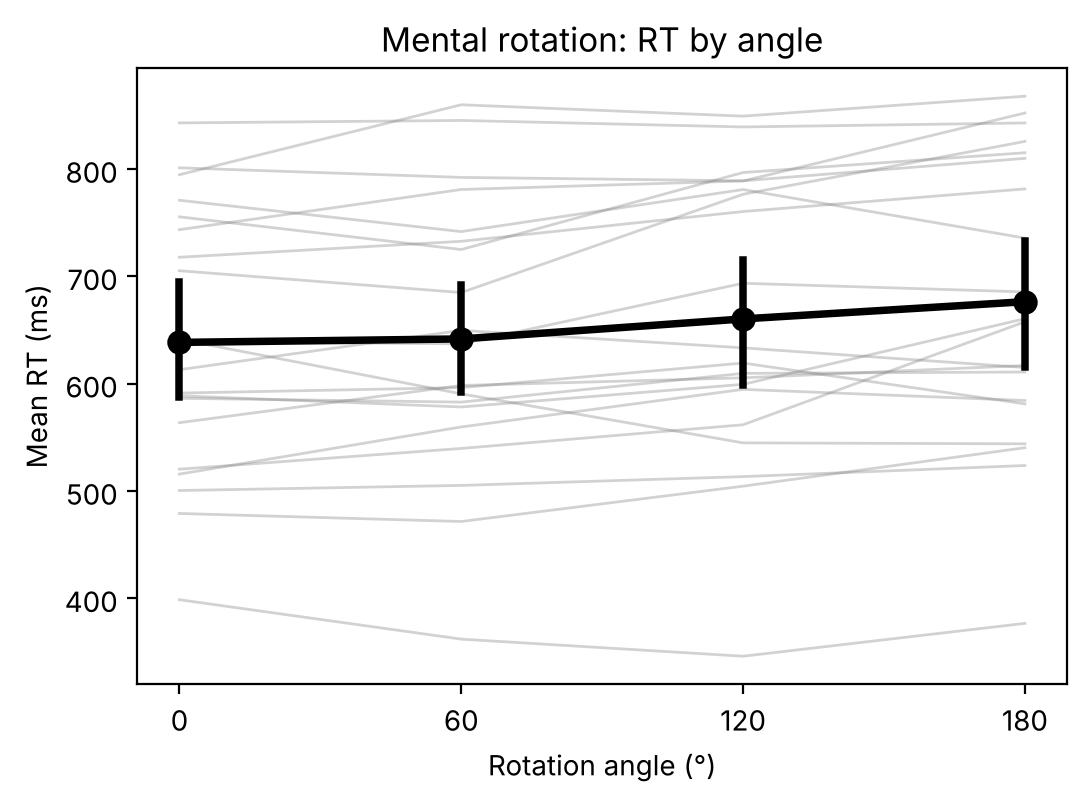

In [9]:
import seaborn as sns
import matplotlib.pyplot as plt

print(agg.groupby("Angle")["RT_ms"].agg(["mean", "std"]).round(1))

fig, ax = plt.subplots(figsize=(6, 4))
sns.lineplot(data=agg, x="Angle", y="RT_ms", units="Participant", estimator=None,
             color="grey", alpha=0.35, lw=1, ax=ax)
sns.pointplot(data=agg, x="Angle", y="RT_ms", errorbar=("ci", 95), color="black",
              native_scale=True, ax=ax)
ax.set(xticks=[0, 60, 120, 180], xlabel="Rotation angle (°)", ylabel="Mean RT (ms)",
       title="Mental rotation: RT by angle")
plt.show()

- Mean RT increases with angle (≈ 639 ms at 0° to ≈ 677 ms at 180°).
- The SDs are large (≈ 125–135 ms) compared with the differences between angles: most variability is **between participants** (baseline speed). An RM design removes this variability from the error term.
- The individual lines have **different slopes**: some participants barely slow down, others slow down a lot. As a result, the differences between far-apart angles (0° vs 180°) vary much more across people than the differences between neighbouring angles (0° vs 60°) → **sphericity is likely violated**.

### Step 5: Normality

Check normality of RT in each angle condition with the Shapiro–Wilk test (`pg.normality`). Is the assumption met?

In [ ]:
import pingouin as pg

# Write your code here

#### ✅ Solution

In [11]:
import pingouin as pg

pg.normality(data=agg, dv="RT_ms", group="Angle")

,W,pval,normal
Angle,,,
0,0.967900,0.710057,True
60,0.976502,0.881436,True
120,0.933185,0.177787,True
180,0.941780,0.259035,True


All Shapiro–Wilk $p$-values are $>.05$ → no evidence against normality in any condition; the normality assumption is met.

### Step 6: RM-ANOVA by Hand

Compute the RM-ANOVA **by hand** with pandas/numpy, using the formulas from the lecture ($k$ = number of conditions, $n$ = number of subjects):

| Quantity | Formula | df |
|---|---|---|
| $SS_T$ | $\sum_i\sum_j (X_{ij}-\bar X_{grand})^2$ | $N-1$ |
| $SS_B$ | $k\sum_i (\bar X_{i\cdot}-\bar X_{grand})^2$ | $n-1$ |
| $SS_W$ | $\sum_i\sum_j (X_{ij}-\bar X_{i\cdot})^2$ | $n(k-1)$ |
| $SS_M$ | $n\sum_j (\bar X_{\cdot j}-\bar X_{grand})^2$ | $k-1$ |
| $SS_R$ | $SS_W-SS_M$ | $(k-1)(n-1)$ |

Then compute $MS_M$, $MS_R$, $F$, and the $p$-value (`scipy.stats.f.sf`). Also verify that $SS_T = SS_B + SS_W$.

In [ ]:
from scipy.stats import f

X = agg["RT_ms"]
grand = ___
subj_mean = ___   # participant mean for each row (hint: groupby + transform)
cond_mean = ___   # condition mean for each row

n = agg["Participant"].nunique()
k = agg["Angle"].nunique()

SS_T = ___
SS_B = ___
SS_W = ___
SS_M = ___
SS_R = ___

df_M = ___
df_R = ___

F = ___
p = ___

#### ✅ Solution

In [13]:
from scipy.stats import f

X = agg["RT_ms"]
grand = X.mean()
subj_mean = agg.groupby("Participant")["RT_ms"].transform("mean")
cond_mean = agg.groupby("Angle")["RT_ms"].transform("mean")

n = agg["Participant"].nunique()
k = agg["Angle"].nunique()

SS_T = ((X - grand) ** 2).sum()
SS_B = ((subj_mean - grand) ** 2).sum()   # each subject mean appears k times -> equals k * sum over subjects
SS_W = ((X - subj_mean) ** 2).sum()
SS_M = ((cond_mean - grand) ** 2).sum()   # each condition mean appears n times -> equals n * sum over conditions
SS_R = SS_W - SS_M

df_M, df_R = k - 1, (k - 1) * (n - 1)
MS_M, MS_R = SS_M / df_M, SS_R / df_R
F = MS_M / MS_R
p = f.sf(F, df_M, df_R)

print(f"SS_T = {SS_T:,.1f}   SS_B + SS_W = {SS_B + SS_W:,.1f}")
print(f"SS_B = {SS_B:,.1f}   (df = {n - 1})")
print(f"SS_W = {SS_W:,.1f}   (df = {n * (k - 1)})")
print(f"SS_M = {SS_M:,.1f}   (df = {df_M})   MS_M = {MS_M:,.1f}")
print(f"SS_R = {SS_R:,.1f}   (df = {df_R})   MS_R = {MS_R:,.1f}")
print(f"F({df_M}, {df_R}) = {F:.2f}, p = {p:.5f}")
print(f"F_crit(.05) = {f.ppf(.95, df_M, df_R):.2f}")

SS_T = 1,315,223.1   SS_B + SS_W = 1,315,223.1
SS_B = 1,247,409.1   (df = 19)
SS_W = 67,814.0   (df = 60)
SS_M = 18,684.6   (df = 3)   MS_M = 6,228.2
SS_R = 49,129.4   (df = 57)   MS_R = 861.9
F(3, 57) = 7.23, p = 0.00034
F_crit(.05) = 2.77


- $SS_T = SS_B + SS_W$ holds exactly.
- $SS_B$ is by far the largest component: most of the variation is **individual differences**, which the RM-ANOVA discards.
- Error df $=(k-1)(n-1)=3\cdot19=57$ (not $N-k=76$ as in an independent ANOVA).
- $F(3,57)\approx 7.2$ is far above $F_{crit}\approx 2.77$ → reject $H_0$ (uncorrected $p<.001$). Whether this survives a sphericity correction is checked in Steps 8–9.

### Step 7: Verify with Pingouin

Run the RM-ANOVA with `pg.rm_anova` (use `detailed=True`, `correction=True` and `effsize="np2"`) and compare SS, df, F and p with your own results. Which row of the Pingouin table corresponds to $SS_R$?

In [ ]:
anova = ___
anova

#### ✅ Solution

In [15]:
anova = pg.rm_anova(data=agg, dv="RT_ms", within="Angle", subject="Participant",
                    detailed=True, correction=True, effsize="np2")
anova

,Source,SS,DF,MS,F,p_unc,p_GG_corr,np2,eps,sphericity,W_spher,p_spher
0,Angle,18684.627381,3,6228.209127,7.225975,0.000342,0.002883,0.275527,0.617794,False,0.40611,0.007021
1,Error,49129.417280,57,861.919601,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


- The `Angle` row matches $SS_M$, $df_M$, $MS_M$, F and p from Step 6; the `Error` row is $SS_R$ with $df_R=57$.
- Pingouin does not show $SS_B$: it is not needed for the F-test.
- Partial $\eta^2 = SS_M/(SS_M+SS_R) = 18{,}685/67{,}814 \approx .28$ (`np2`).
- The table already shows the Greenhouse–Geisser $\hat\varepsilon$ (`eps`), the GG-corrected p (`p_GG_corr`), and Mauchly's test (`W_spher`, `p_spher`, `sphericity`). We look at these next.

### Step 8: Sphericity

1. **By hand:** reshape `agg` to wide format (one column per angle), compute all **6 pairwise difference scores**, and their variances.
2. **Mauchly's test:** run `pg.sphericity`.

### Questions
- Which difference scores have the largest/smallest variance? Relate this to the spaghetti plot.
- What do you conclude from Mauchly's test?

In [ ]:
from itertools import combinations

wide = ___   # rows = participants, columns = angles

# variances of pairwise differences
# Write your code here

# Mauchly
# Write your code here

#### ✅ Solution

In [17]:
from itertools import combinations

wide = agg.pivot(index="Participant", columns="Angle", values="RT_ms")

diff_var = {f"{a}° − {b}°": (wide[a] - wide[b]).var() for a, b in combinations(wide.columns, 2)}
print(pd.Series(diff_var).round(0).sort_values())

print()
print(pg.sphericity(data=agg, dv="RT_ms", within="Angle", subject="Participant"))

0° − 60°        892.0
60° − 120°     1026.0
120° − 180°    1173.0
0° − 120°      1672.0
60° − 180°     2391.0
0° − 180°      3189.0
dtype: float64

SpherResults(spher=False, W=np.float64(0.40610969142436026), chi2=np.float64(15.970061200212182), dof=5, pval=np.float64(0.007020857181096748))


- The variances of the difference scores are **far from equal**: neighbouring angles (e.g., 0°−60°) have small variances; the most distant angles (0°−180°) have by far the largest. Participants differ in their rotation **slope**, so the gap between 0° and 180° varies a lot between people.
- Mauchly: $p<.05$ → $H_0$ (sphericity) is **rejected** → **sphericity is violated**.
- Consequence: the uncorrected F-test has an inflated Type I error rate → we need a correction.

### Step 9: Sphericity Corrections

1. Use `pg.epsilon` to obtain the **Greenhouse–Geisser** (`"gg"`), **Huynh–Feldt** (`"hf"`) and **lower-bound** (`"lb"`) epsilons.
2. For each, compute the corrected df and corrected $p$ **by hand** (multiply both df by $\hat\varepsilon$, keep F).
3. Check that your GG-corrected $p$ matches Pingouin's `p_GG_corr`.

### Questions
- Which correction should be reported according to the 0.75 rule?
- Does the conclusion change?

In [ ]:
eps = {}
for corr in ["gg", "hf", "lb"]:
    eps[corr] = ___

# corrected df and p
# Write your code here

#### ✅ Solution

In [19]:
eps = {corr: pg.epsilon(data=agg, dv="RT_ms", within="Angle", subject="Participant", correction=corr)
       for corr in ["gg", "hf", "lb"]}

rows = []
for corr, e in eps.items():
    d1, d2 = e * df_M, e * df_R
    rows.append({"correction": corr, "epsilon": e, "df1": d1, "df2": d2, "F": F, "p": f.sf(F, d1, d2)})
rows.append({"correction": "none", "epsilon": 1, "df1": df_M, "df2": df_R, "F": F, "p": p})
print(pd.DataFrame(rows).round(4))
print("\nPingouin p_GG_corr:", anova.loc[0, "p_GG_corr"].round(4))

  correction  epsilon     df1      df2      F       p
0         gg   0.6178  1.8534  35.2142  7.226  0.0029
1         hf   0.6817  2.0452  38.8581  7.226  0.0020
2         lb   0.3333  1.0000  19.0000  7.226  0.0146
3       none   1.0000  3.0000  57.0000  7.226  0.0003

Pingouin p_GG_corr: 0.0029


- $\hat\varepsilon_{GG}\approx0.62$, $\hat\varepsilon_{HF}\approx0.68$; lower bound $=1/(k-1)=0.33$.
- GG is the most conservative of the two estimates; HF is more liberal; the lower bound is the most conservative of all.
- Both estimates are **below 0.75** → report **Greenhouse–Geisser**: $F(1.85, 35.21)=7.23,\ p=.003$.
- F is identical in every row; only df and p change. The effect remains significant under every correction (even the lower bound, $p\approx.015$).

### Step 10: Post Hoc Tests

Run all pairwise comparisons between angles with `pg.pairwise_tests`.

### Questions
- Which p-value adjustment should you use here, and why?
- Which pairs of angles differ significantly?

In [ ]:
posthoc = ___
posthoc

#### ✅ Solution

In [21]:
posthoc = pg.pairwise_tests(data=agg, dv="RT_ms", within="Angle", subject="Participant",
                            padjust="bonf")
posthoc[["A", "B", "T", "dof", "p_unc", "p_corr", "hedges"]].round(4)

,A,B,T,dof,p_unc,p_corr,hedges
0,0,60,-0.4827,19.0,0.6348,1.0000,-0.0250
1,0,120,-2.3925,19.0,0.0272,0.1634,-0.1661
2,0,180,-3.0036,19.0,0.0073,0.0438,-0.2867
3,60,120,-2.6033,19.0,0.0175,0.1048,-0.1389
4,60,180,-3.1738,19.0,0.0050,0.0300,-0.2574
5,120,180,-2.0965,19.0,0.0497,0.2980,-0.1167


- Sphericity is violated → use **Bonferroni**-corrected pairwise comparisons (Tukey is only appropriate when sphericity holds).
- With 6 comparisons, each uncorrected p is multiplied by 6.
- After correction, only **0° vs 180°** ($p_{bonf}=.044$) and **60° vs 180°** ($p_{bonf}=.030$) remain significant. Several pairs that were significant uncorrected (e.g., 0° vs 120°, 60° vs 120°) no longer are. The omnibus F alone could not tell us which pairs differ.

### Step 11: One Step Further: Why Use a Repeated-Measures Design?

Run an **independent** one-way ANOVA (`pg.anova` with `between="Angle"`) on the same aggregated data, i.e., pretend that every cell comes from a different person.

### Questions
- Compare F and p with the RM-ANOVA.
- Show numerically that the independent error SS equals $SS_B + SS_R$.

In [ ]:
indep = ___
indep

#### ✅ Solution

In [23]:
indep = pg.anova(data=agg, dv="RT_ms", between="Angle", detailed=True)
print(indep.round(4))
print(f"\nIndependent error SS = {indep.loc[1, 'SS']:,.1f}")
print(f"SS_B + SS_R          = {SS_B + SS_R:,.1f}")

   Source            SS  DF          MS       F   p_unc     np2
0   Angle  1.868463e+04   3   6228.2091  0.3651  0.7784  0.0142
1  Within  1.296538e+06  76  17059.7169     NaN     NaN     NaN

Independent error SS = 1,296,538.5
SS_B + SS_R          = 1,296,538.5


- The effect SS ($SS_M$) is the same in both analyses, but the independent ANOVA uses $SS_B+SS_R$ as error, with $df=N-k=76$.
- Because $SS_B$ (individual differences) is huge, the independent F drops below 1 and the effect is **not significant** ($p\approx.78$), whereas the RM-ANOVA finds a clear effect.
- **Take-home:** removing individual differences from the error term is the source of the RM design's power. Analysing dependent data as independent is not only wrong (it violates independence) but also throws that power away.

### Finally: Report the Result

**Question:** Write a short results paragraph (APA style) including the assumption checks, the corrected test, an effect size, and the post hoc results.

### Answer

> Shapiro–Wilk tests indicated no deviations from normality in any condition (all $p>.05$). Mauchly's test showed that sphericity was violated, $W=0.41,\ p=.007$. As $\hat\varepsilon<0.75$, Greenhouse–Geisser-corrected degrees of freedom are reported ($\hat\varepsilon=0.62$). Rotation angle had a significant effect on reaction time, $F(1.85, 35.21)=7.23,\ p=.003,\ \eta^2_p=.28$. Bonferroni-corrected pairwise comparisons showed that RTs at 180° were slower than at 0° ($p=.044$) and at 60° ($p=.030$); no other pairs differed significantly.

Checklist: F, (corrected) df and p ✓ · sphericity result + correction ✓ · effect size ✓ · corrected post hoc tests ✓.